# Virginia Climate Center - Energy Assistance Programming and Climate Relationships

This notebook is a starting point for analysis in this repository. The Python project configuration and `.venv` are at the repository root.

### Virginia Energy Assistance Programming Notes
Virginia's Energy Assistance Program (EAP) supports low income households meet their home energy needs. EAP is administered by the Virginia Department of Social Services, and has four parts:

- Fuel assistance: offsets heating fuel costs
  - One time heating benefit toward heating costs, can cover fuel, delivery, late charges, and connection or restart fees. Amount is set by a point system (income, heat type, climate zone, vulnerability). Reapply every year.
  - Application window is mid October to mid November, and payments start in January
- Crisis assistance: helps with heating emergencies
  - Crisis: equipment, deposits, shelter
    - Heating equipment repair or replacement, space heaters, one-time heat security deposit, emergency shelter
    - Nov 1 to Mar 15, payments start immediately upon application approval
  - Crisis: fuel and utility bills
    - Purchase of primary heating fuel and payment of heat utility bills
    - First workday of January to March 15, payments start immediately upon application approval
- Cooling assistance: helps with cooling bills and equipment
  - One-time electric bill payment, electric security deposit, central AC or heat pump repair, whole-house fan, window unit
  - June 15 to August 15
  - One time benefit, payment upon application approval
  - Household needs a person 60 or older, a person with a disability, or a child under 6. First-come, first-served, only when federal funds allow. 
- Weatherization assistance: improves energy efficiency and reduces costs
  - Not relevant to seasonal changes, pertains more to energy equipment upgrades

To qualify, you must have heating/cooling expenses and have a gross monthly income that is 150% of the federal poverty level.

LIHEAP was established shortly after the 1970s oil crisis to primarily help residences pay for heating. As of 2024, LIHEAP allocates over half its funding to heating assistance, with less than 10 % supporting cooling assistance despite increasing demand for air conditioning amid rising temperatures due to climate change


### Main analysis questions
- How have monthly HDD and CDD changed across periods? And how have they changed since LIHEAP was introduced?
- Is cooling demand spreading outside June to August? And by how much?
- Does the heating window line up with the heating need? The fuel application window (mid-October to mid-November) comes before most demand, and payments arrive in January. When do HDD actually peak, and has that shifted?
- Does the crisis window cover the cold months? Crisis runs through March 15. How much heating demand falls after that date, in late March and April?
- Do regions differ? Could repeat the analysis by climate division (Virginia has several). The regulation uses six NOAA zones for heating benefits.

In [1]:
import sys

import matplotlib
import numpy
import pandas as pd
import scipy
import seaborn
from pathlib import Path

### Load and process HDD and CDD data

Monthly HDD/CDD state data was pulled from NOAA's monthly archived datasets. Each file has a 10-character identifier followed by January–December values. The identifier contains the area code (3 digits), division number (1 digit), element code (2 digits), and year (4 digits). For example, `0010261895` means area `001`, division `0`, CDD element `26`, year `1895`; HDD uses element `25`. The cell below reads both files and splits the identifier into separate columns.

Virginia is in area `044`

In [2]:
data_dir = Path("data") if Path("data").is_dir() else Path("../data")
months = ["january", "february", "march", "april", "may", "june",
          "july", "august", "september", "october", "november", "december"]
columns = ["record_id", *months]
widths = [10, *([7] * 12)]

hdd_df = pd.read_fwf(
    data_dir / "climdiv-hddcst-v1.0.0-20261006.txt",
    widths=widths,
    names=columns,
    dtype={"record_id": "string"},
    na_values=["-9999."],
)
cdd_df = pd.read_fwf(
    data_dir / "climdiv-cddcst-v1.0.0-20261006.txt",
    widths=widths,
    names=columns,
    dtype={"record_id": "string"},
    na_values=["-9999."],
)

for df in (hdd_df, cdd_df):
    df["area_code"] = df["record_id"].str[:3]
    df["division_number"] = df["record_id"].str[3:4].astype(int)
    df["element_code"] = df["record_id"].str[4:6]
    df["year"] = df["record_id"].str[6:10].astype(int)

display(hdd_df.head())
display(cdd_df.head())

,record_id,january,february,march,april,may,june,july,august,september,october,november,december,area_code,division_number,element_code,year
0,0010251895,717.0,800.0,373.0,115.0,34.0,0.0,0.0,0.0,0.0,234.0,377.0,646.0,001,0,25,1895
1,0010251896,693.0,517.0,429.0,47.0,4.0,0.0,0.0,0.0,4.0,147.0,275.0,603.0,001,0,25,1896
2,0010251897,752.0,422.0,239.0,135.0,39.0,0.0,0.0,0.0,2.0,75.0,355.0,573.0,001,0,25,1897
3,0010251898,545.0,556.0,246.0,229.0,8.0,0.0,0.0,0.0,3.0,181.0,478.0,694.0,001,0,25,1898
4,0010251899,690.0,732.0,342.0,148.0,3.0,0.0,0.0,0.0,10.0,87.0,321.0,661.0,001,0,25,1899


,record_id,january,february,march,april,may,june,july,august,september,october,november,december,area_code,division_number,element_code,year
0,0010261895,5.0,0.0,18.0,49.0,155.0,359.0,419.0,437.0,365.0,28.0,4.0,1.0,001,0,26,1895
1,0010261896,4.0,3.0,12.0,118.0,320.0,354.0,488.0,522.0,305.0,60.0,20.0,2.0,001,0,26,1896
2,0010261897,3.0,10.0,55.0,38.0,143.0,464.0,496.0,414.0,309.0,121.0,8.0,3.0,001,0,26,1897
3,0010261898,19.0,2.0,45.0,13.0,268.0,446.0,457.0,421.0,298.0,37.0,1.0,1.0,001,0,26,1898
4,0010261899,5.0,0.0,24.0,32.0,331.0,436.0,466.0,490.0,225.0,105.0,12.0,2.0,001,0,26,1899


## Filter for Virginia data

In [3]:
va_hdd_df = hdd_df[hdd_df["area_code"]== "044"]
va_cdd_df = cdd_df[cdd_df["area_code"]== "044"]

In [4]:
bins = [1894, 1950, 1990, 2025]
labels = ["1895-1950", "1951-1990", "1991-2025"]

# reshape the dataframe and aggregate statistics 
hdd_long = va_hdd_df.melt(
    id_vars=["area_code", "year"],
    value_vars=months,
    var_name="month",
    value_name="hdd",
)

hdd_long["period"] = pd.cut(hdd_long["year"], bins=bins, labels=labels)

hdd_long["month"] = pd.Categorical(hdd_long["month"], categories=months, ordered=True)

hdd_stats = (
    hdd_long.dropna(subset=["period"])
    .groupby(["area_code", "period", "month"], observed=True)["hdd"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

hdd_stats.head()

,area_code,period,month,mean,std,min,max
0,044,1895-1950,january,925.660714,147.148568,581.0,1304.0
1,044,1895-1950,february,819.142857,125.992558,604.0,1108.0
2,044,1895-1950,march,629.928571,128.406295,334.0,870.0
3,044,1895-1950,april,345.625000,69.570778,215.0,521.0
4,044,1895-1950,may,106.928571,40.922035,33.0,213.0


In [5]:
# Reshape the CDD dataframe and aggregate statistics 
cdd_long = va_cdd_df.melt(
    id_vars=["area_code", "year"],
    value_vars=months,
    var_name="month",
    value_name="cdd",
)

cdd_long["period"] = pd.cut(cdd_long["year"], bins=bins, labels=labels)

cdd_long["month"] = pd.Categorical(cdd_long["month"], categories=months, ordered=True)

cdd_stats = (
    cdd_long.dropna(subset=["period"])
    .groupby(["area_code", "period", "month"], observed=True)["cdd"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

## Plotting

In [6]:
import matplotlib.pyplot as plt

hdd_mean = hdd_stats.pivot(index="month", columns="period",values=["mean","std"])
cdd_mean = cdd_stats.pivot(index="month",columns="period",values= ["mean","std"])

In [7]:
# Add program windows on plots, functions

import calendar

def xpos(month, day, months):
    i = months.index(month)
    month_len = calendar.monthrange(2001, list(calendar.month_name).index(month.title()))[1]
    return i - 0.5 + day / month_len

hdd_windows = [  
    ("Fuel assistance",           ("october", 15),  ("november", 15), "tab:purple"),
    ("Crisis: heating emergency",  ("november", 1),  ("march", 16),    "tab:orange"),
    ("Crisis: fuel/utility bills", ("january", 1),   ("march", 15),    "tab:blue"),
]
cdd_windows = [
    ("Cooling assistance",        ("june", 15),     ("august", 15),   "tab:green"),
]

def add_windows(windows, months):
    for label, (sm, sd), (em, ed), color in windows:
        a, b = xpos(sm, sd, months), xpos(em, ed, months)
        plt.axvline(a, color=color, linestyle=":", linewidth=2, label=label)  # label once per window
        plt.axvline(b, color=color, linestyle=":", linewidth=2)



In [8]:
# Define months for HDD, CDD, all months

hdd_months = ["september", "october", "november", "december",
              "january", "february", "march", "april"]
cdd_months = ["may", "june", "july", "august", "september", "october"]

all_months = [ "january", "february", "march", "april",
               "may", "june", "july", "august",
               "september", "october", "november", "december"]

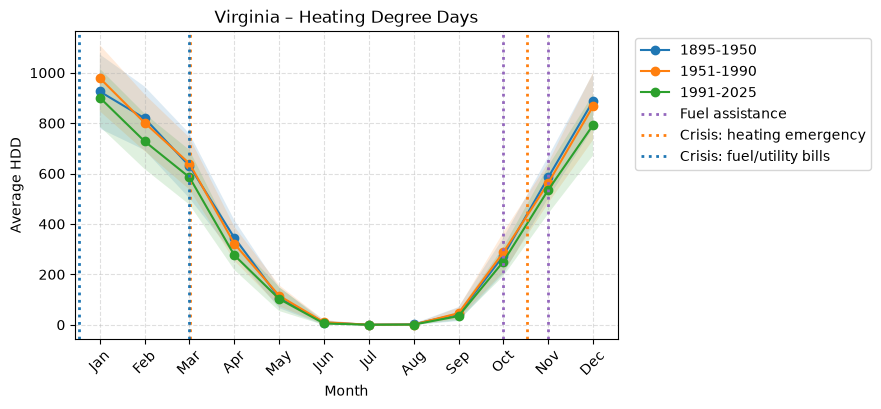

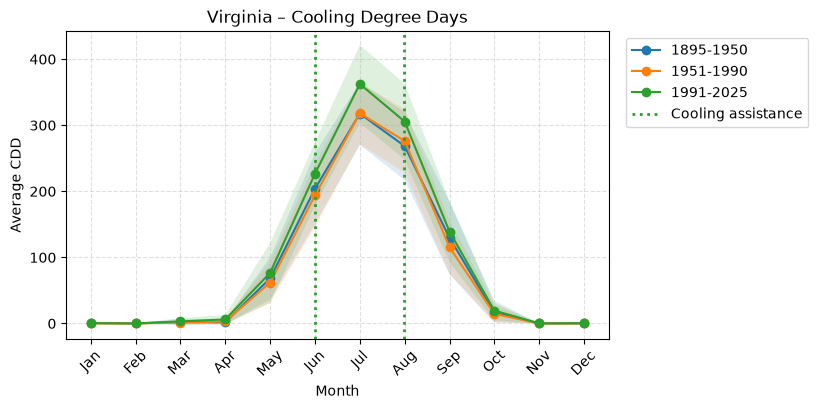

In [9]:
# Plot average monthly HDD across periods 
x = range(12)
plt.figure(figsize=(7, 4))
for period in ["1895-1950", "1951-1990", "1991-2025"]:
    m, s = hdd_mean["mean"][period], hdd_mean["std"][period]
    plt.plot(x, m, marker="o", label=period)
    plt.fill_between(x, m - s, m + s, alpha=0.15)

add_windows(hdd_windows, all_months)
plt.xticks(x, [m[:3].title() for m in hdd_mean.index], rotation=45)
plt.xlabel("Month")
plt.ylabel("Average HDD")
plt.title("Virginia – Heating Degree Days")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True, linestyle="--", alpha=0.4) 
plt.show()

# Plot average monthly CDD across periods 
x = range(12)
plt.figure(figsize=(7, 4))
for period in ["1895-1950", "1951-1990", "1991-2025"]:
    m, s = cdd_mean["mean"][period], cdd_mean["std"][period]
    plt.plot(x, m, marker="o", label=period)
    plt.fill_between(x, m - s, m + s, alpha=0.15)
add_windows(cdd_windows, all_months)
plt.xticks(x, [m[:3].title() for m in cdd_mean.index], rotation=45)
plt.xlabel("Month")
plt.ylabel("Average CDD")
plt.title("Virginia – Cooling Degree Days")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True, linestyle="--", alpha=0.4) 
plt.show()

- HDD seems to have decreased looking between the pre-1990 periods and the 1991-2025 period, by how much? Can we zoom in on the winter months?
- CDD seems to have significantly increased between the pre-1990 periods and the 1991-2025 period, by how much? And are shoulder months also seeing hotter days? Can we zoom in on the summer months?

### Can we isolate the winter and summer months?

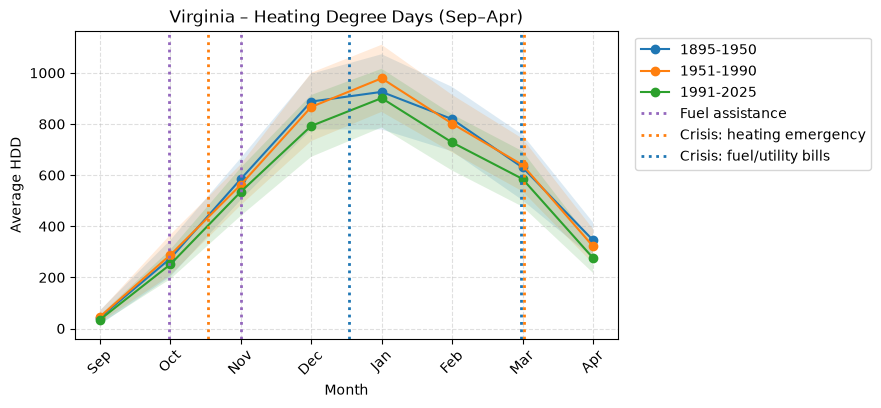

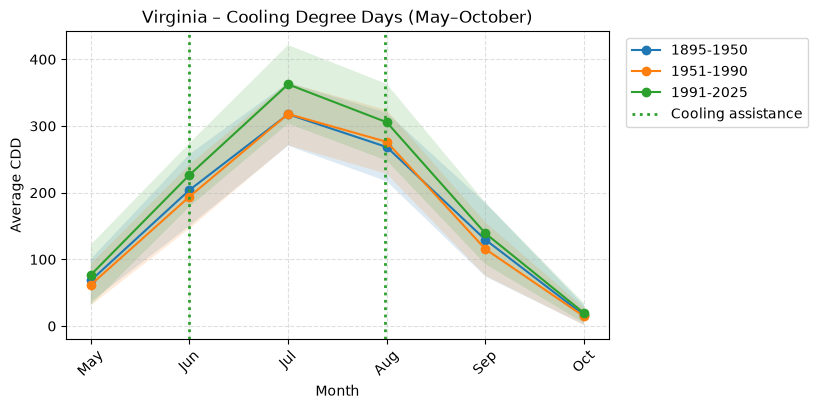

In [10]:
# HDD
hdd_sel = hdd_mean.loc[hdd_months]      # keep only these months, in this order

x = range(len(hdd_months))
plt.figure(figsize=(7, 4))
for period in ["1895-1950", "1951-1990", "1991-2025"]:
    m, s = hdd_sel["mean"][period], hdd_sel["std"][period]
    plt.plot(x, m, marker="o", label=period)
    plt.fill_between(x, m - s, m + s, alpha=0.15)

add_windows(hdd_windows, hdd_months)
plt.xticks(x, [name[:3].title() for name in hdd_sel.index], rotation=45)
plt.xlabel("Month")
plt.ylabel("Average HDD")
plt.title("Virginia – Heating Degree Days (Sep–Apr)")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# CDD
cdd_sel = cdd_mean.loc[cdd_months]      # keep only these months, in this order

x = range(len(cdd_months))
plt.figure(figsize=(7, 4))
for period in ["1895-1950", "1951-1990", "1991-2025"]:
    m, s = cdd_sel["mean"][period], cdd_sel["std"][period]
    plt.plot(x, m, marker="o", label=period)
    plt.fill_between(x, m - s, m + s, alpha=0.15)
add_windows(cdd_windows, cdd_months)
plt.xticks(x, [name[:3].title() for name in cdd_sel.index], rotation=45)
plt.xlabel("Month")
plt.ylabel("Average CDD")
plt.title("Virginia – Cooling Degree Days (May–October)")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

### Monthly percent and absolute change between time periods? 

In [11]:
def pct_change(mean_df, old, new, months):
    m = mean_df["mean"].loc[months]
    return (m[new] - m[old]) / m[old] * 100

def abs_change(mean_df, old, new, months):
    m = mean_df["mean"].loc[months]
    return m[new] - m[old]

old1, old2, new = "1895-1950", "1951-1990", "1991-2025"
bins   = [1894, 1950, 1990, 2025]
labels = [old1, old2, new]

hdd_pct = pd.DataFrame({
    "1895-1950 → 1991-2025": pct_change(hdd_mean, old1, new, all_months),
    "1951-1990 → 1991-2025": pct_change(hdd_mean, old2, new, all_months),
}).round(1)

cdd_pct = pd.DataFrame({
    "1895-1950 → 1991-2025": pct_change(cdd_mean, old1, new, all_months),
    "1951-1990 → 1991-2025": pct_change(cdd_mean, old2, new, all_months),
}).round(1)

hdd_abs = pd.DataFrame({
    "1895-1950 → 1991-2025": abs_change(hdd_mean, old1, new, all_months),
    "1951-1990 → 1991-2025": abs_change(hdd_mean, old2, new, all_months),
}).round(1)

cdd_abs = pd.DataFrame({
    "1895-1950 → 1991-2025": abs_change(cdd_mean, old1, new, all_months),
    "1951-1990 → 1991-2025": abs_change(cdd_mean, old2, new, all_months),
}).round(1)

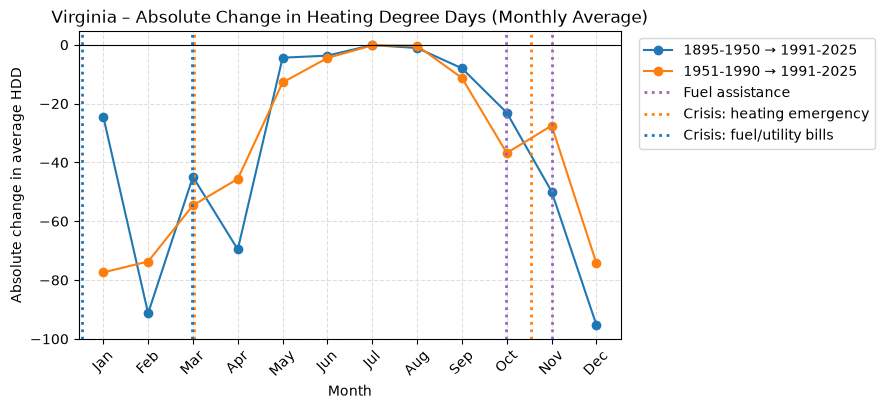

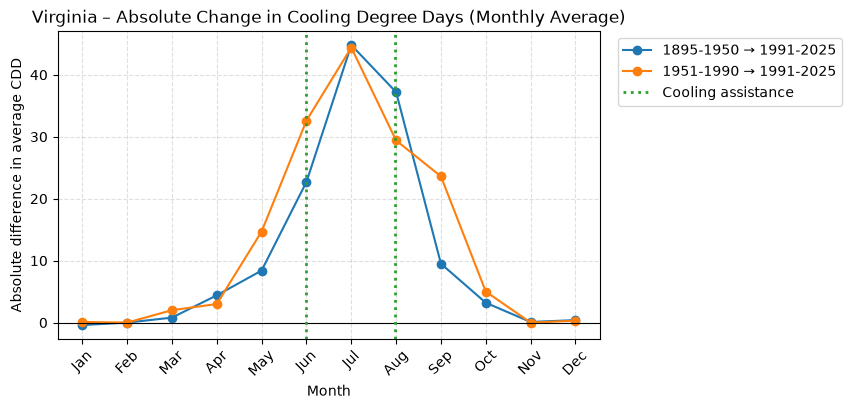

In [12]:
# HDD absolute change
hdd_sel = hdd_abs.loc[all_months]    

x = range(len(all_months))
plt.figure(figsize=(7, 4))
for comparison in ["1895-1950 → 1991-2025", "1951-1990 → 1991-2025"]:
    plt.plot(x, hdd_sel[comparison], marker="o", label=comparison)
plt.axhline(0, color="black", linewidth=0.8)     
add_windows(hdd_windows, all_months)
plt.xticks(x, [name[:3].title() for name in hdd_sel.index], rotation=45)
plt.xlabel("Month")
plt.ylabel("Absolute change in average HDD")
plt.title("Virginia – Absolute Change in Heating Degree Days (Monthly Average)")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# CDD absolute change
cdd_sel = cdd_abs.loc[all_months]      # keep only these months, in this order

x = range(len(all_months))
plt.figure(figsize=(7, 4))
for comparison in ["1895-1950 → 1991-2025", "1951-1990 → 1991-2025"]:
    plt.plot(x, cdd_sel[comparison], marker="o", label=comparison)
plt.axhline(0, color="black", linewidth=0.8)  
add_windows(cdd_windows, all_months)
plt.xticks(x, [name[:3].title() for name in cdd_sel.index], rotation=45)
plt.xlabel("Month")
plt.ylabel("Absolute difference in average CDD")
plt.title("Virginia – Absolute Change in Cooling Degree Days (Monthly Average)")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

The plots above denote a general decrease in heating degree days and simultaneous increase in cooling degree days. Heating demand has more assistance allocation than cooling demand, although CDDs are increasing outside of the assistance program windows.

##### - Are there opportunities to adjust funding resources from heating to cooling? Extending cooling assistance funding periods as peak demand seasons evolve?
##### - How does communication and the type of agency impact program reach? Do other states have higher participation in LIHEAP because of this?
##### - What is the significance of the increase in CDD? How much does it actually impact energy bills relative to a baseline?